In [4]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import random

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.4.6


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seeds configured successfully.")

Random seeds configured successfully.


## Loading dataset

In [ ]:


(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Exploring the dataset

In [6]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [7]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Total classes:", len(class_names))

Total classes: 10


In [8]:
print("\nPixel Value Range")
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Pixel Value Range
Minimum pixel value: 0
Maximum pixel value: 255


In [9]:
print("Training images:", x_train.dtype)
print("Training labels:", y_train.dtype)

print("Testing images:", x_test.dtype)
print("Testing labels:", y_test.dtype)

Training images: uint8
Training labels: uint8
Testing images: uint8
Testing labels: uint8


### Class Distribution

In [10]:
class_counts = pd.Series(y_train).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Class ID": range(10),
    "Image Count": class_counts.values
})

display(class_distribution)

,Class,Class ID,Image Count
0,T-shirt/top,0,6000
1,Trouser,1,6000
2,Pullover,2,6000
3,Dress,3,6000
4,Coat,4,6000
5,Sandal,5,6000
6,Shirt,6,6000
7,Sneaker,7,6000
8,Bag,8,6000
9,Ankle boot,9,6000


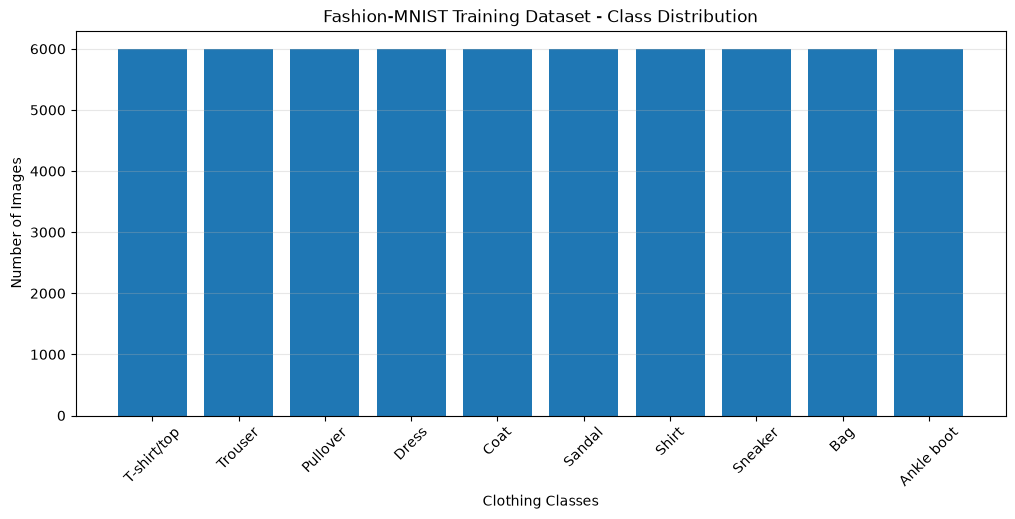

In [13]:
plt.figure(figsize=(12, 5))

plt.bar(class_names, class_counts.values)

plt.title("Fashion-MNIST Training Dataset - Class Distribution")
plt.xlabel("Clothing Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Visualizing each classes

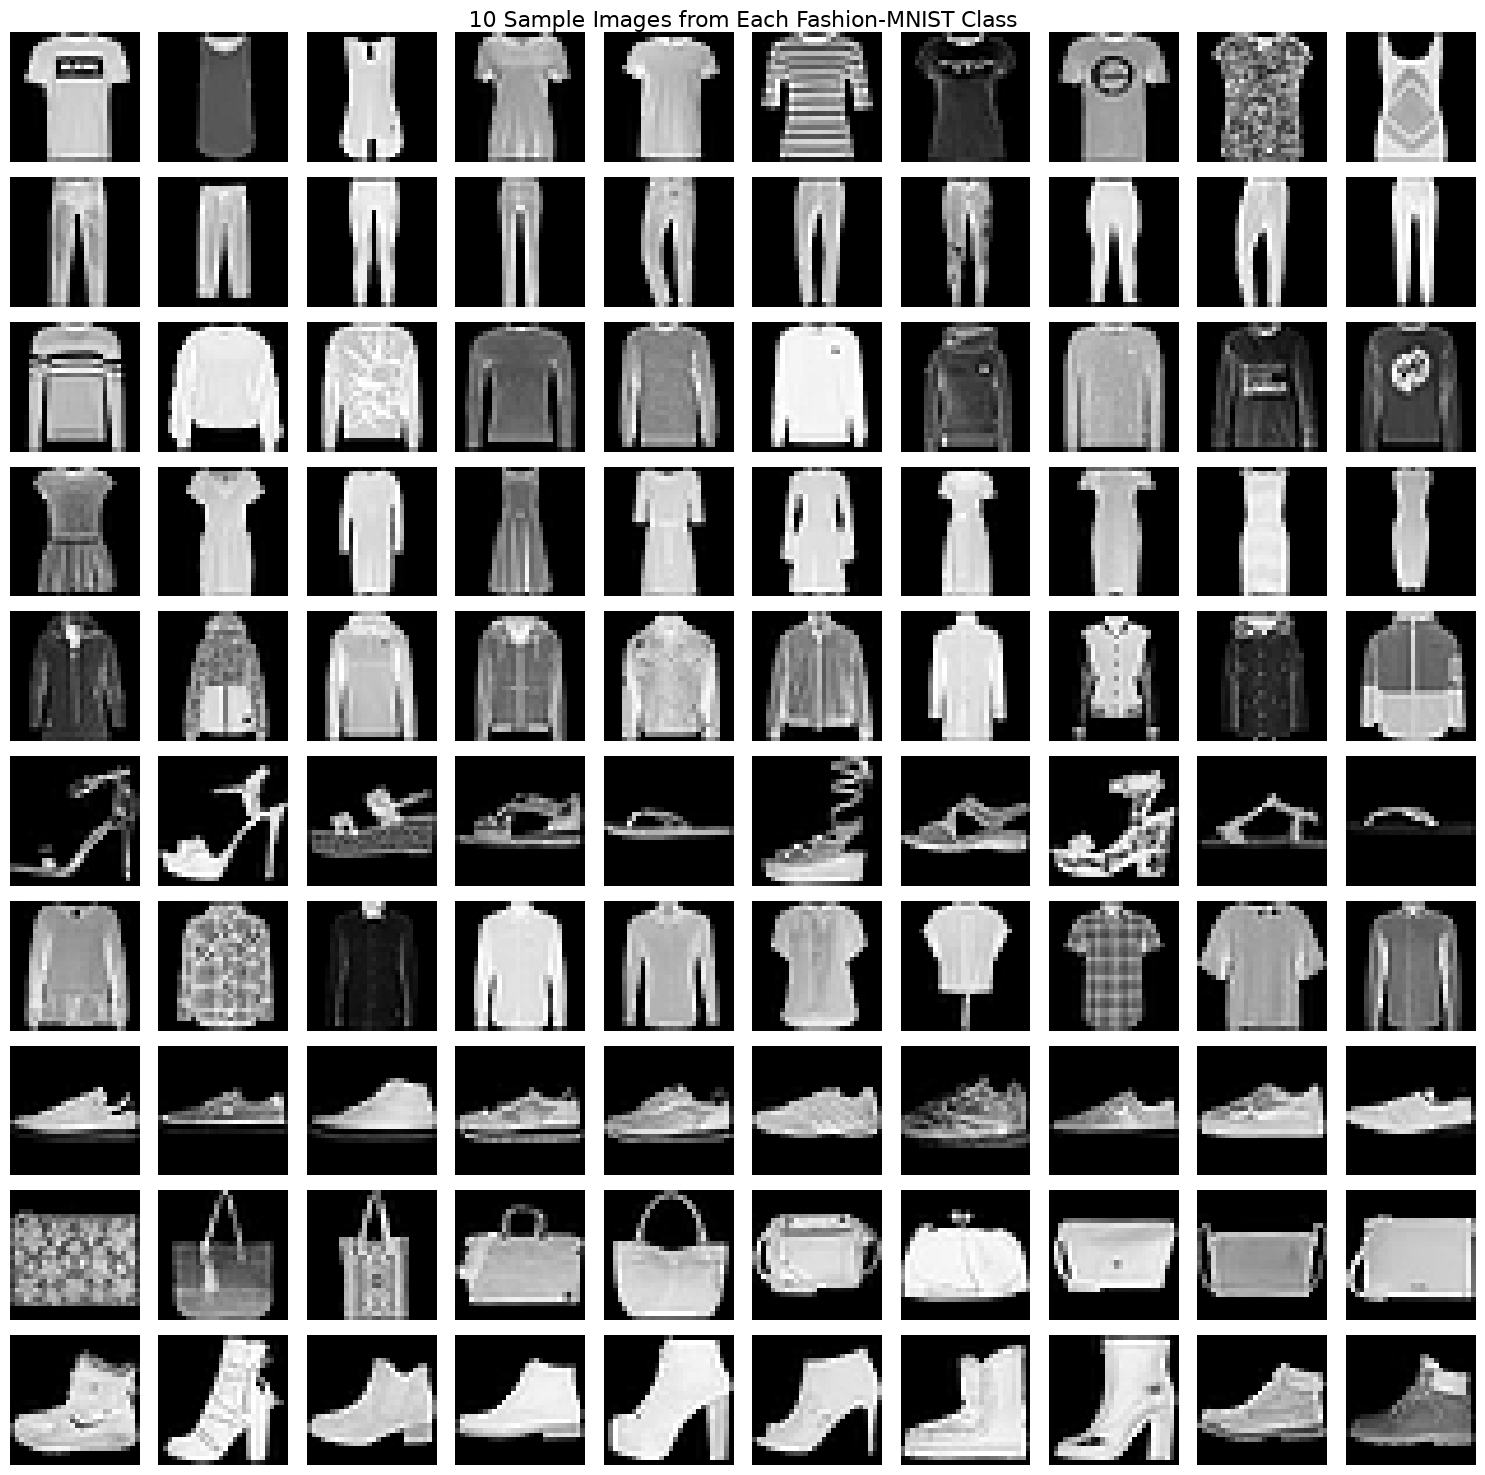

In [14]:
plt.figure(figsize=(15, 15))

for class_id in range(10):
    class_indices = np.where(y_train == class_id)[0][:10]

    for image_number, image_index in enumerate(class_indices):
        plt.subplot(10, 10, class_id * 10 + image_number + 1)

        plt.imshow(x_train[image_index], cmap="gray")
        plt.axis("off")

        if image_number == 0:
            plt.ylabel(
                class_names[class_id],
                fontsize=9
            )

plt.suptitle("10 Sample Images from Each Fashion-MNIST Class", fontsize=16)
plt.tight_layout()
plt.show()

In [17]:
print("Pixel Intensity Statistics")
print("--------------------------")

print("Minimum:", np.min(x_train))
print("Maximum:", np.max(x_train))
print("Mean:", np.mean(x_train))
print("Median:", np.median(x_train))
print("Standard Deviation:", np.std(x_train))

Pixel Intensity Statistics
--------------------------
Minimum: 0
Maximum: 255
Mean: 72.94035223214286
Median: 0.0
Standard Deviation: 90.02118235130526


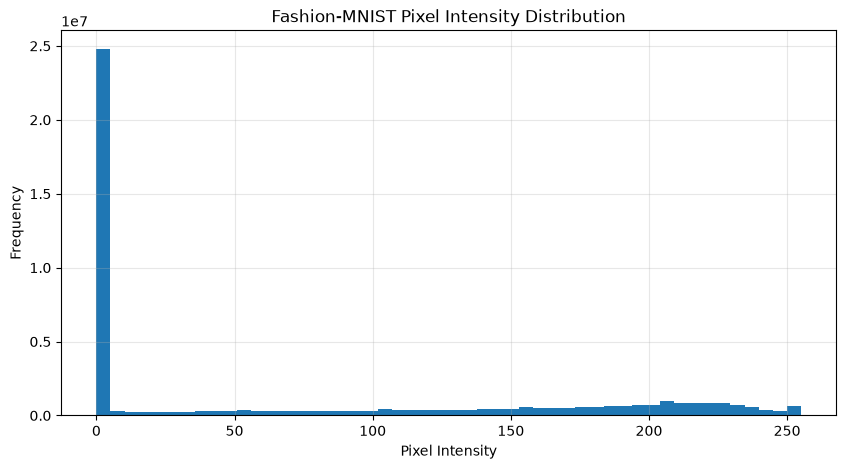

In [16]:
plt.figure(figsize=(10, 5))

plt.hist(x_train.flatten(), bins=50)

plt.title("Fashion-MNIST Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()

### Data Preprocessing

### Normalizing the images

In [19]:
# Normalize pixel values from 0-255 to 0-1

x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

print("Before Normalization:")
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

print("\nAfter Normalization:")
print("Minimum:", x_train_normalized.min())
print("Maximum:", x_train_normalized.max())
print("Mean:", x_train_normalized.mean())
print("Standard Deviation:", x_train_normalized.std())

Before Normalization:
Minimum: 0
Maximum: 255

After Normalization:
Minimum: 0.0
Maximum: 1.0
Mean: 0.2860406
Standard Deviation: 0.35302424


In [20]:
x_train_split, x_val, y_train_split, y_val = train_test_split(
    x_train_normalized,
    y_train,
    test_size=10000,
    random_state=SEED,
    stratify=y_train
)

print("Training Set:", x_train_split.shape)
print("Training Labels:", y_train_split.shape)

print("\nValidation Set:", x_val.shape)
print("Validation Labels:", y_val.shape)

print("\nTest Set:", x_test_normalized.shape)
print("Test Labels:", y_test.shape)

Training Set: (50000, 28, 28)
Training Labels: (50000,)

Validation Set: (10000, 28, 28)
Validation Labels: (10000,)

Test Set: (10000, 28, 28)
Test Labels: (10000,)


### Splitting for validation set

In [21]:
split_distribution = pd.DataFrame({
    "Class": class_names,
    "Training": np.bincount(y_train_split, minlength=10),
    "Validation": np.bincount(y_val, minlength=10),
    "Test": np.bincount(y_test, minlength=10)
})

display(split_distribution)

,Class,Training,Validation,Test
0,T-shirt/top,5000,1000,1000
1,Trouser,5000,1000,1000
2,Pullover,5000,1000,1000
3,Dress,5000,1000,1000
4,Coat,5000,1000,1000
5,Sandal,5000,1000,1000
6,Shirt,5000,1000,1000
7,Sneaker,5000,1000,1000
8,Bag,5000,1000,1000
9,Ankle boot,5000,1000,1000


### Prepare images shapes for training

In [22]:
# Add channel dimension for CNN

x_train_cnn = np.expand_dims(x_train_split, axis=-1)
x_val_cnn = np.expand_dims(x_val, axis=-1)
x_test_cnn = np.expand_dims(x_test_normalized, axis=-1)

print("CNN Training Shape:", x_train_cnn.shape)
print("CNN Validation Shape:", x_val_cnn.shape)
print("CNN Testing Shape:", x_test_cnn.shape)

CNN Training Shape: (50000, 28, 28, 1)
CNN Validation Shape: (10000, 28, 28, 1)
CNN Testing Shape: (10000, 28, 28, 1)


## Building Stage 1 MLP Model

In [23]:
from tensorflow.keras import layers, models

mlp_model = models.Sequential([
    layers.Input(shape=(28, 28)),

    layers.Flatten(),

    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(10, activation="softmax")
])

mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
mlp_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [25]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start_time = time.time()

mlp_history = mlp_model.fit(
    x_train_split,
    y_train_split,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

mlp_training_time = time.time() - start_time

print("MLP Training Time:", round(mlp_training_time, 2), "seconds")
print("Total Epochs:", len(mlp_history.history["loss"]))

Epoch 1/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7779 - loss: 0.6256 - val_accuracy: 0.8573 - val_loss: 0.3957
Epoch 2/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8413 - loss: 0.4372 - val_accuracy: 0.8655 - val_loss: 0.3681
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8535 - loss: 0.3982 - val_accuracy: 0.8769 - val_loss: 0.3388
Epoch 4/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8630 - loss: 0.3722 - val_accuracy: 0.8815 - val_loss: 0.3252
Epoch 5/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8690 - loss: 0.3542 - val_accuracy: 0.8835 - val_loss: 0.3216
Epoch 6/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8728 - loss: 0.3413 - val_accuracy: 0.8850 - val_loss: 0.3160
Epoch 7/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8787 - loss: 0.3263 - val_accuracy: 0.8885 - val_loss: 0.3101
Epoch 8/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8816 - loss: 0.3167 - val_accuracy: 0.

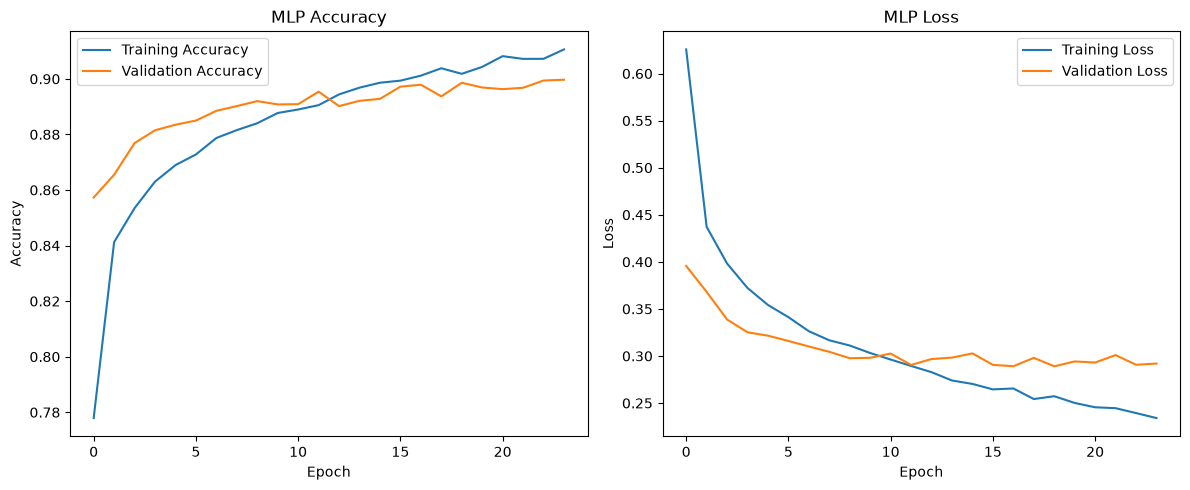

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mlp_history.history["accuracy"], label="Training Accuracy")
plt.plot(mlp_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MLP Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(mlp_history.history["loss"], label="Training Loss")
plt.plot(mlp_history.history["val_loss"], label="Validation Loss")
plt.title("MLP Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
os.makedirs("../models", exist_ok=True)

mlp_model.save("../models/mlp_model.keras")

# MLP Model Observation:

** The MLP model achieved 91.06% training accuracy and
89.97% validation accuracy in 24 epochs.

The model completed training in 55.35 seconds.
The small difference between training and validation
accuracy indicates reasonable generalization.

A slight difference between training and validation
loss suggests mild overfitting.

The model successfully exceeded the required 87%
accuracy target for the MLP baseline. **

## Building the CNN Model

In [28]:
cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification Head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(10, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

In [29]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

In [31]:
start_time = time.time()

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train_split,
    validation_data=(x_val_cnn, y_val),
    epochs=30,
    batch_size=128,
    callbacks=cnn_callbacks,
    verbose=1
)

cnn_training_time = time.time() - start_time

print("CNN Training Time:", round(cnn_training_time, 2), "seconds")
print("Total Epochs:", len(cnn_history.history["loss"]))

Epoch 1/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - accuracy: 0.7917 - loss: 0.5920 - val_accuracy: 0.8341 - val_loss: 0.6138 - learning_rate: 0.0010
Epoch 2/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 35s 91ms/step - accuracy: 0.8595 - loss: 0.3894 - val_accuracy: 0.8866 - val_loss: 0.3130 - learning_rate: 0.0010
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - accuracy: 0.8754 - loss: 0.3414 - val_accuracy: 0.9030 - val_loss: 0.2632 - learning_rate: 0.0010
Epoch 4/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 41s 104ms/step - accuracy: 0.8877 - loss: 0.3092 - val_accuracy: 0.9016 - val_loss: 0.2600 - learning_rate: 0.0010
Epoch 5/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 37s 94ms/step - accuracy: 0.8958 - loss: 0.2862 - val_accuracy: 0.9013 - val_loss: 0.2608 - learning_rate: 0.0010
Epoch 6/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 34s 87ms/step - accuracy: 0.9017 - loss: 0.2657 - val_accuracy: 0.9155 - val_loss: 0.2325 - learning_rate: 0.0010
Epoch 7/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 36s 93ms/step - accuracy: 0.9070 -

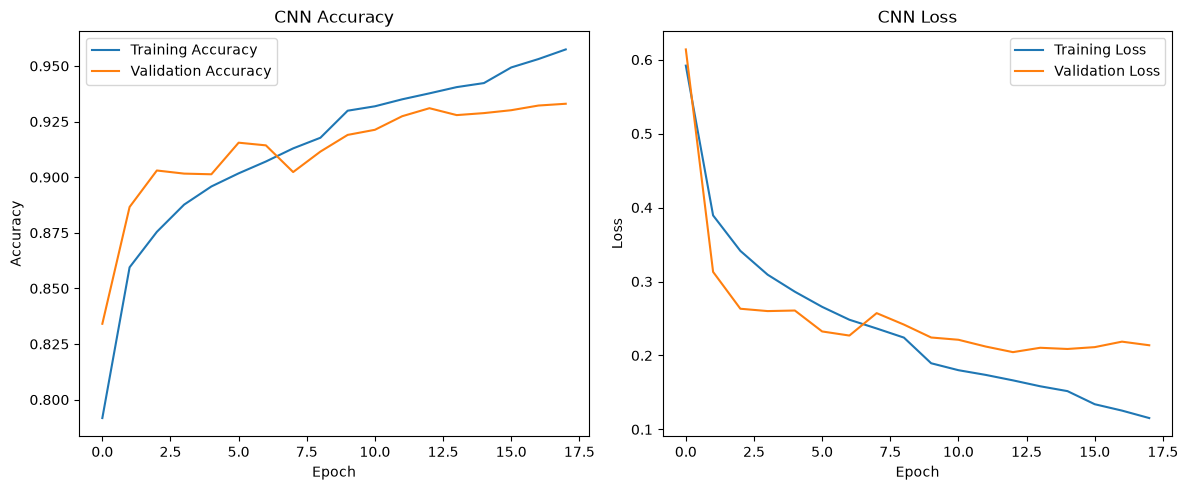

In [32]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [33]:
cnn_model.save("../models/cnn_model.keras")

### Model Observation
CNN Model Observation

The CNN achieved 95.74% training accuracy and 93.30% validation accuracy after 18 epochs. It successfully exceeded the required 91% validation accuracy target. Compared with the MLP baseline, CNN improved validation accuracy by 3.33 percentage points. Convolutional layers helped the model learn spatial features and image patterns more effectively.

### MLP vs CNN comparison
#### Metric	MLP	CNN
#### Training accuracy	91.06%	95.74%
#### Validation accuracy	89.97%	93.30%
#### Training loss	0.2341	0.1153
#### Validation loss	0.2920	0.2138

## Improvement of the cnn model

### S1) Data Augmentation

In [34]:
data_augmentation = models.Sequential([
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),

    layers.RandomZoom(
        height_factor=0.1,
        width_factor=0.1
    ),

    layers.RandomFlip("horizontal")
], name="data_augmentation")

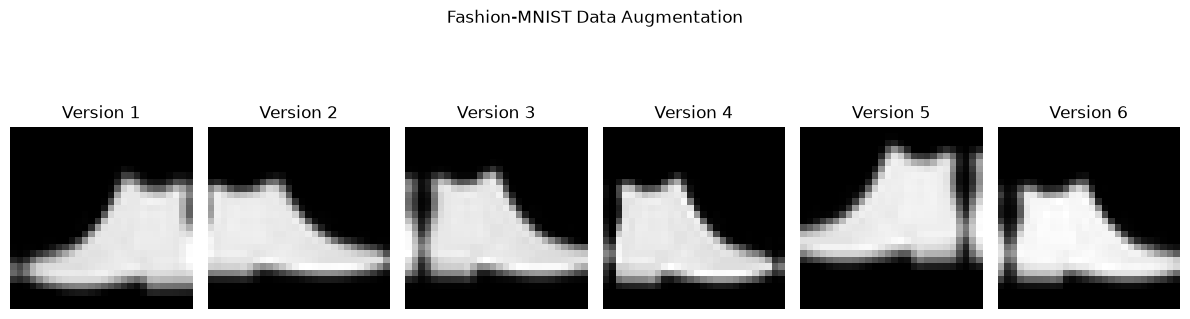

In [36]:
# Observing augmentation

sample_image = x_train_cnn[0]

plt.figure(figsize=(12, 4))

for i in range(6):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )

    plt.subplot(1, 6, i + 1)
    plt.imshow(augmented_image[0].numpy().squeeze(), cmap="gray")
    plt.axis("off")
    plt.title(f"Version {i+1}")

plt.suptitle("Fashion-MNIST Data Augmentation")
plt.tight_layout()
plt.show()

## Improved CNN Model

In [37]:
improved_cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Data Augmentation
    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Classification Head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    layers.Dense(10, activation="softmax")
])

improved_cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 469,098 (1.79 MB)

 Trainable params: 468,458 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

In [38]:
improved_cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [39]:
improved_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "../models/improved_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [40]:
start_time = time.time()

improved_history = improved_cnn_model.fit(
    x_train_cnn,
    y_train_split,
    validation_data=(x_val_cnn, y_val),
    epochs=40,
    batch_size=128,
    callbacks=improved_callbacks,
    verbose=1
)

improved_training_time = time.time() - start_time

print("Improved CNN Training Time:",
      round(improved_training_time, 2), "seconds")

print("Total Epochs:",
      len(improved_history.history["loss"]))

Epoch 1/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.7272 - loss: 0.7468
Epoch 1: val_loss improved from None to 1.75942, saving model to ../models/improved_cnn_best.keras

Epoch 1: finished saving model to ../models/improved_cnn_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 99s 240ms/step - accuracy: 0.7272 - loss: 0.7468 - val_accuracy: 0.4050 - val_loss: 1.7594 - learning_rate: 0.0010
Epoch 2/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - accuracy: 0.8072 - loss: 0.5194
Epoch 2: val_loss improved from 1.75942 to 0.41146, saving model to ../models/improved_cnn_best.keras

Epoch 2: finished saving model to ../models/improved_cnn_best.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 94s 240ms/step - accuracy: 0.8072 - loss: 0.5194 - val_accuracy: 0.8445 - val_loss: 0.4115 - learning_rate: 0.0010
Epoch 3/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.8316 - loss: 0.4560
Epoch 3: val_loss improved from 0.41146 to 0.35624, saving model to ../models/improved_cnn_best.keras

Epoch 

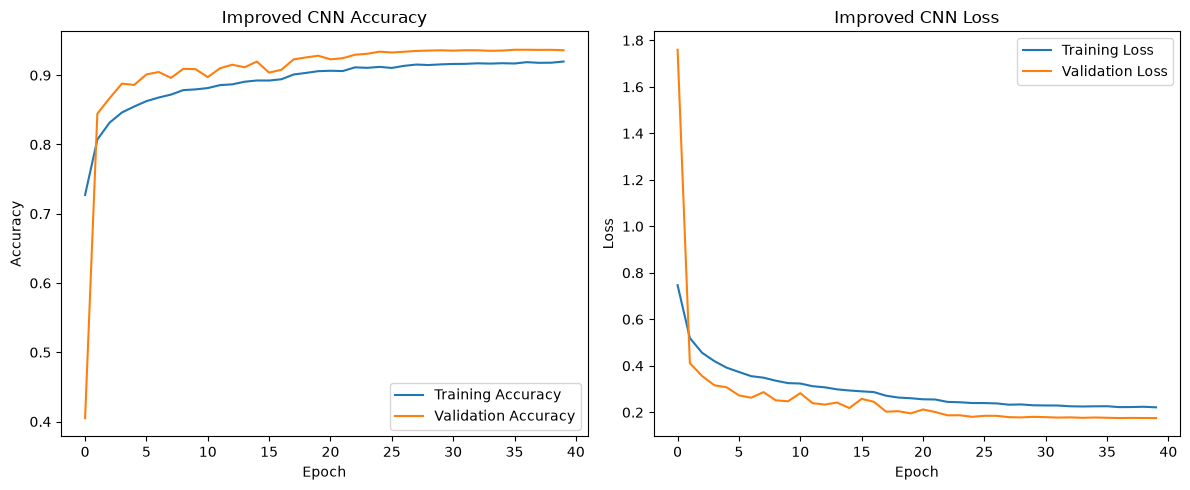

In [41]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(improved_history.history["accuracy"],
         label="Training Accuracy")
plt.plot(improved_history.history["val_accuracy"],
         label="Validation Accuracy")
plt.title("Improved CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(improved_history.history["loss"],
         label="Training Loss")
plt.plot(improved_history.history["val_loss"],
         label="Validation Loss")
plt.title("Improved CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [42]:
improved_cnn_model.save("../models/improved_cnn_model.keras")

Improved CNN Model Observation

The improved CNN achieved 91.98% training accuracy and 93.61% validation accuracy. It exceeded the required 92.5% target. Data augmentation and the deeper CNN architecture helped improve validation performance. Validation accuracy was slightly higher than training accuracy, which can occur because augmentation and dropout are active during training but disabled during validation.

Metric	MLP	CNN	Improved CNN
#### Training accuracy	91.06%	95.74%	91.98%
#### Validation accuracy	89.97%	93.30%	93.61%
#### Training loss	0.2341	0.1153	0.2215
#### Validation loss	0.2920	0.2138	0.1753

In [43]:
# Evaluate all three models on the test dataset

mlp_test_loss, mlp_test_accuracy = mlp_model.evaluate(
    x_test_normalized,
    y_test,
    verbose=1
)

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

improved_test_loss, improved_test_accuracy = improved_cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

print("\nFinal Test Accuracy")
print("-------------------")

print("MLP:", round(mlp_test_accuracy * 100, 2), "%")
print("CNN:", round(cnn_test_accuracy * 100, 2), "%")
print("Improved CNN:", round(improved_test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8838 - loss: 0.3324
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9204 - loss: 0.2371
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9244 - loss: 0.2008

Final Test Accuracy
-------------------
MLP: 88.38 %
CNN: 92.04 %
Improved CNN: 92.44 %


## Classification Report

In [44]:
from sklearn.metrics import classification_report

# Generate predictions using Improved CNN
y_pred_prob = improved_cnn_model.predict(
    x_test_cnn,
    verbose=1
)

y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step
              precision    recall  f1-score   support

 T-shirt/top     0.8821    0.8680    0.8750      1000
     Trouser     0.9919    0.9810    0.9864      1000
    Pullover     0.8972    0.9080    0.9026      1000
       Dress     0.9249    0.9110    0.9179      1000
        Coat     0.8669    0.8990    0.8827      1000
      Sandal     0.9919    0.9750    0.9834      1000
       Shirt     0.7734    0.7680    0.7707      1000
     Sneaker     0.9428    0.9890    0.9653      1000
         Bag     0.9910    0.9920    0.9915      1000
  Ankle boot     0.9855    0.9530    0.9690      1000

    accuracy                         0.9244     10000
   macro avg     0.9248    0.9244    0.9244     10000
weighted avg     0.9248    0.9244    0.9244     10000



## Confusion Matrix

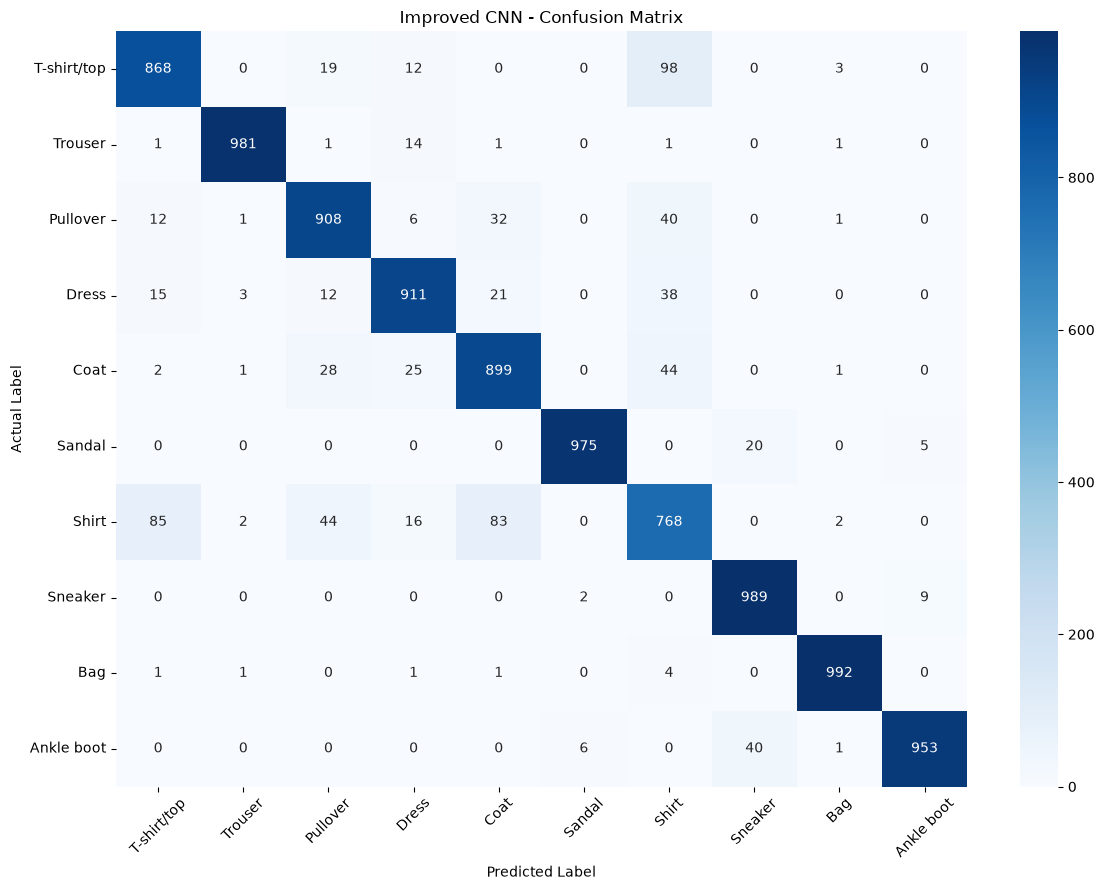

In [45]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Improved CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## Confused Pairs

In [46]:
confused_pairs = []

for i in range(10):
    for j in range(i + 1, 10):

        confusion_count = cm[i, j] + cm[j, i]

        confused_pairs.append({
            "Class Pair": f"{class_names[i]} ↔ {class_names[j]}",
            "Confusion Count": confusion_count
        })

confused_pairs = sorted(
    confused_pairs,
    key=lambda x: x["Confusion Count"],
    reverse=True
)

print("Top 2 Most Confused Class Pairs")

for pair in confused_pairs[:2]:
    print(pair)

Top 2 Most Confused Class Pairs
{'Class Pair': 'T-shirt/top ↔ Shirt', 'Confusion Count': np.int64(183)}
{'Class Pair': 'Coat ↔ Shirt', 'Confusion Count': np.int64(127)}


## Prediction Visualization

In [47]:
# Get predictions from the Improved CNN
y_pred_prob = improved_cnn_model.predict(x_test_cnn, verbose=1)

# Predicted class and confidence
y_pred = np.argmax(y_pred_prob, axis=1)
confidence = np.max(y_pred_prob, axis=1)

# Select 25 random test images
np.random.seed(SEED)
sample_indices = np.random.choice(
    len(x_test_cnn), size=25, replace=False
)

print("Selected 25 test images successfully.")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
Selected 25 test images successfully.


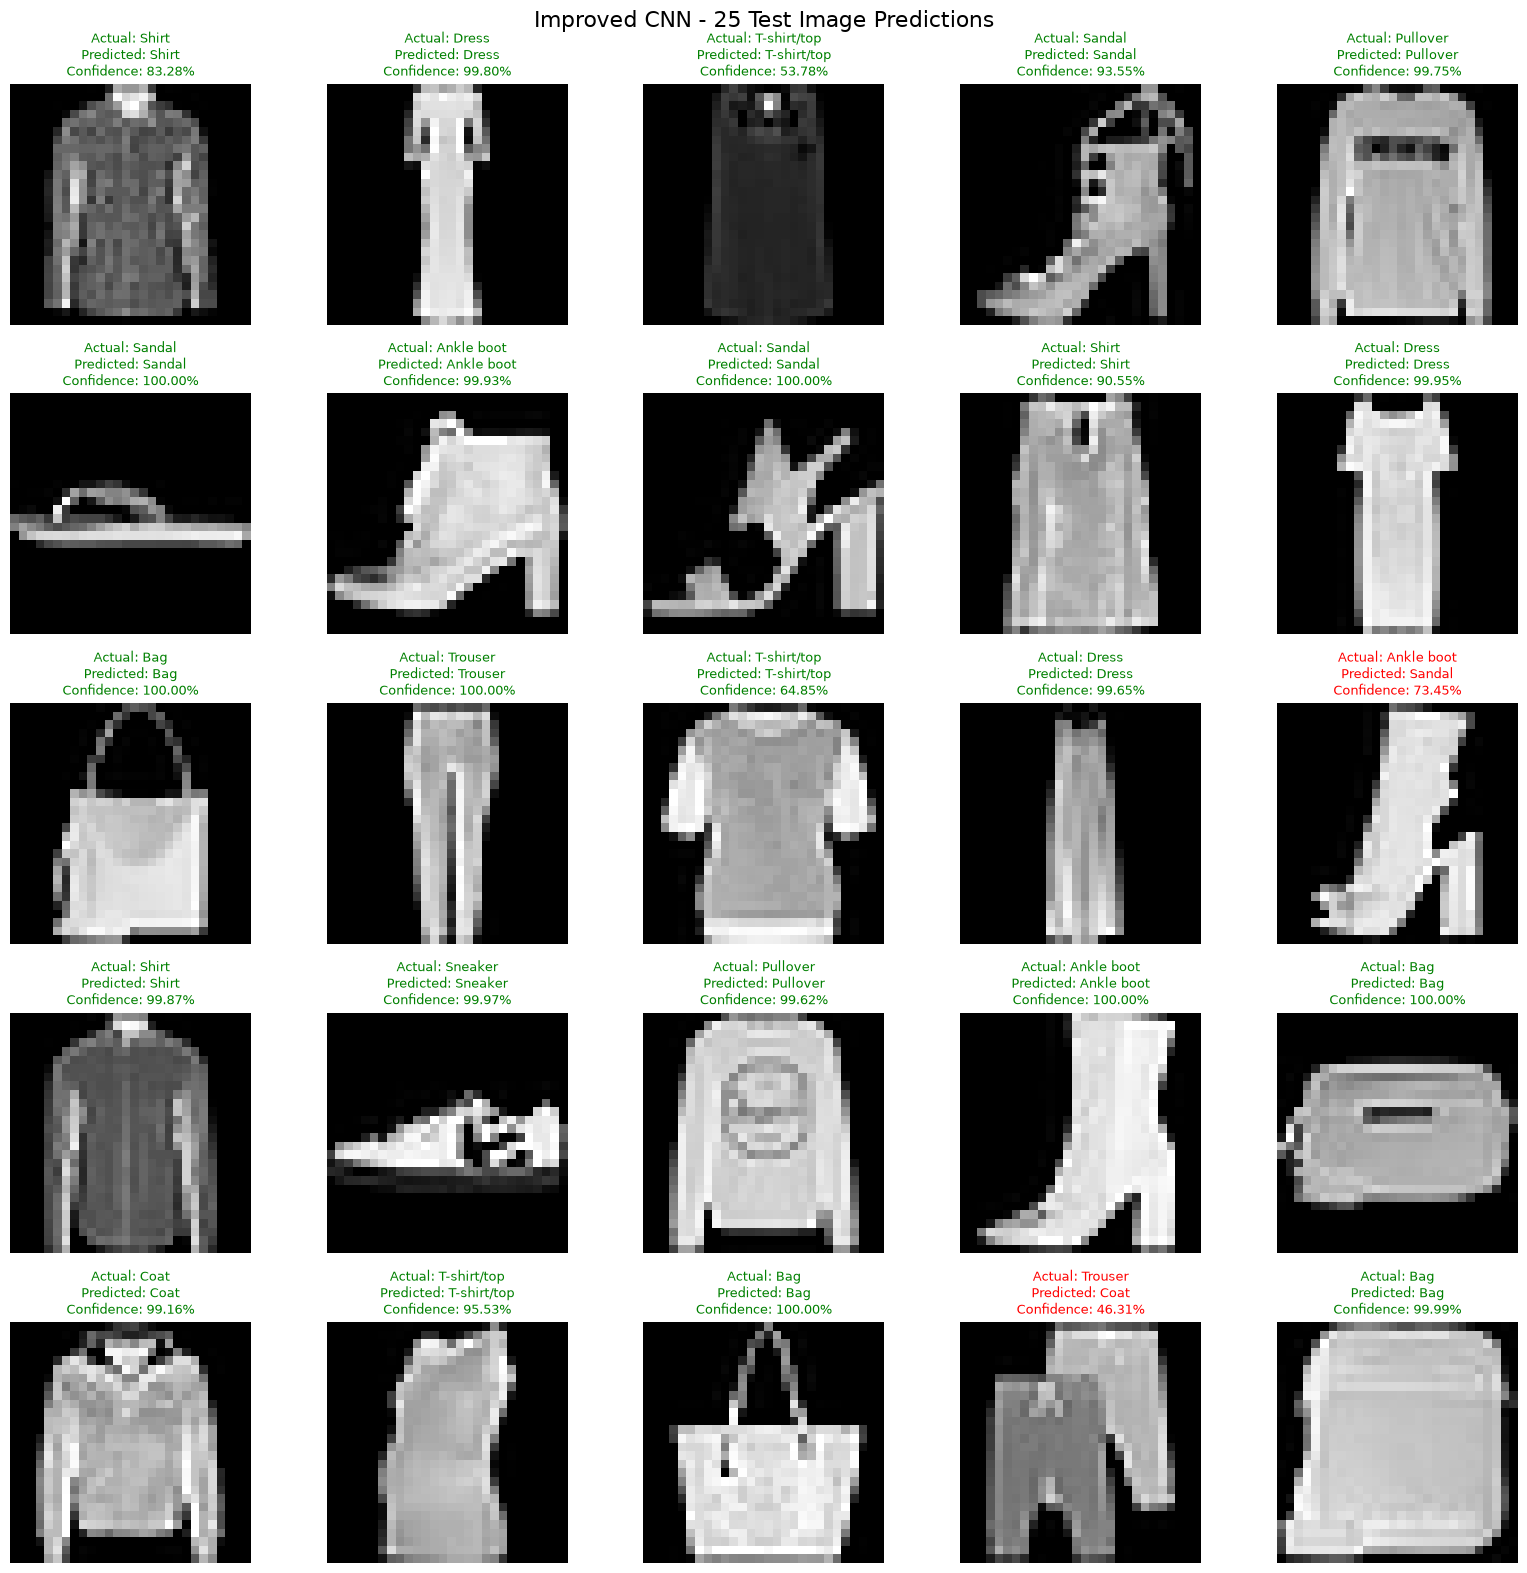

In [48]:
plt.figure(figsize=(16, 16))

for position, index in enumerate(sample_indices):
    actual = y_test[index]
    predicted = y_pred[index]
    conf = confidence[index]

    plt.subplot(5, 5, position + 1)
    plt.imshow(x_test[index], cmap="gray")

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}\n"
        f"Confidence: {conf:.2%}",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.suptitle(
    "Improved CNN - 25 Test Image Predictions",
    fontsize=16
)
plt.tight_layout()
plt.show()

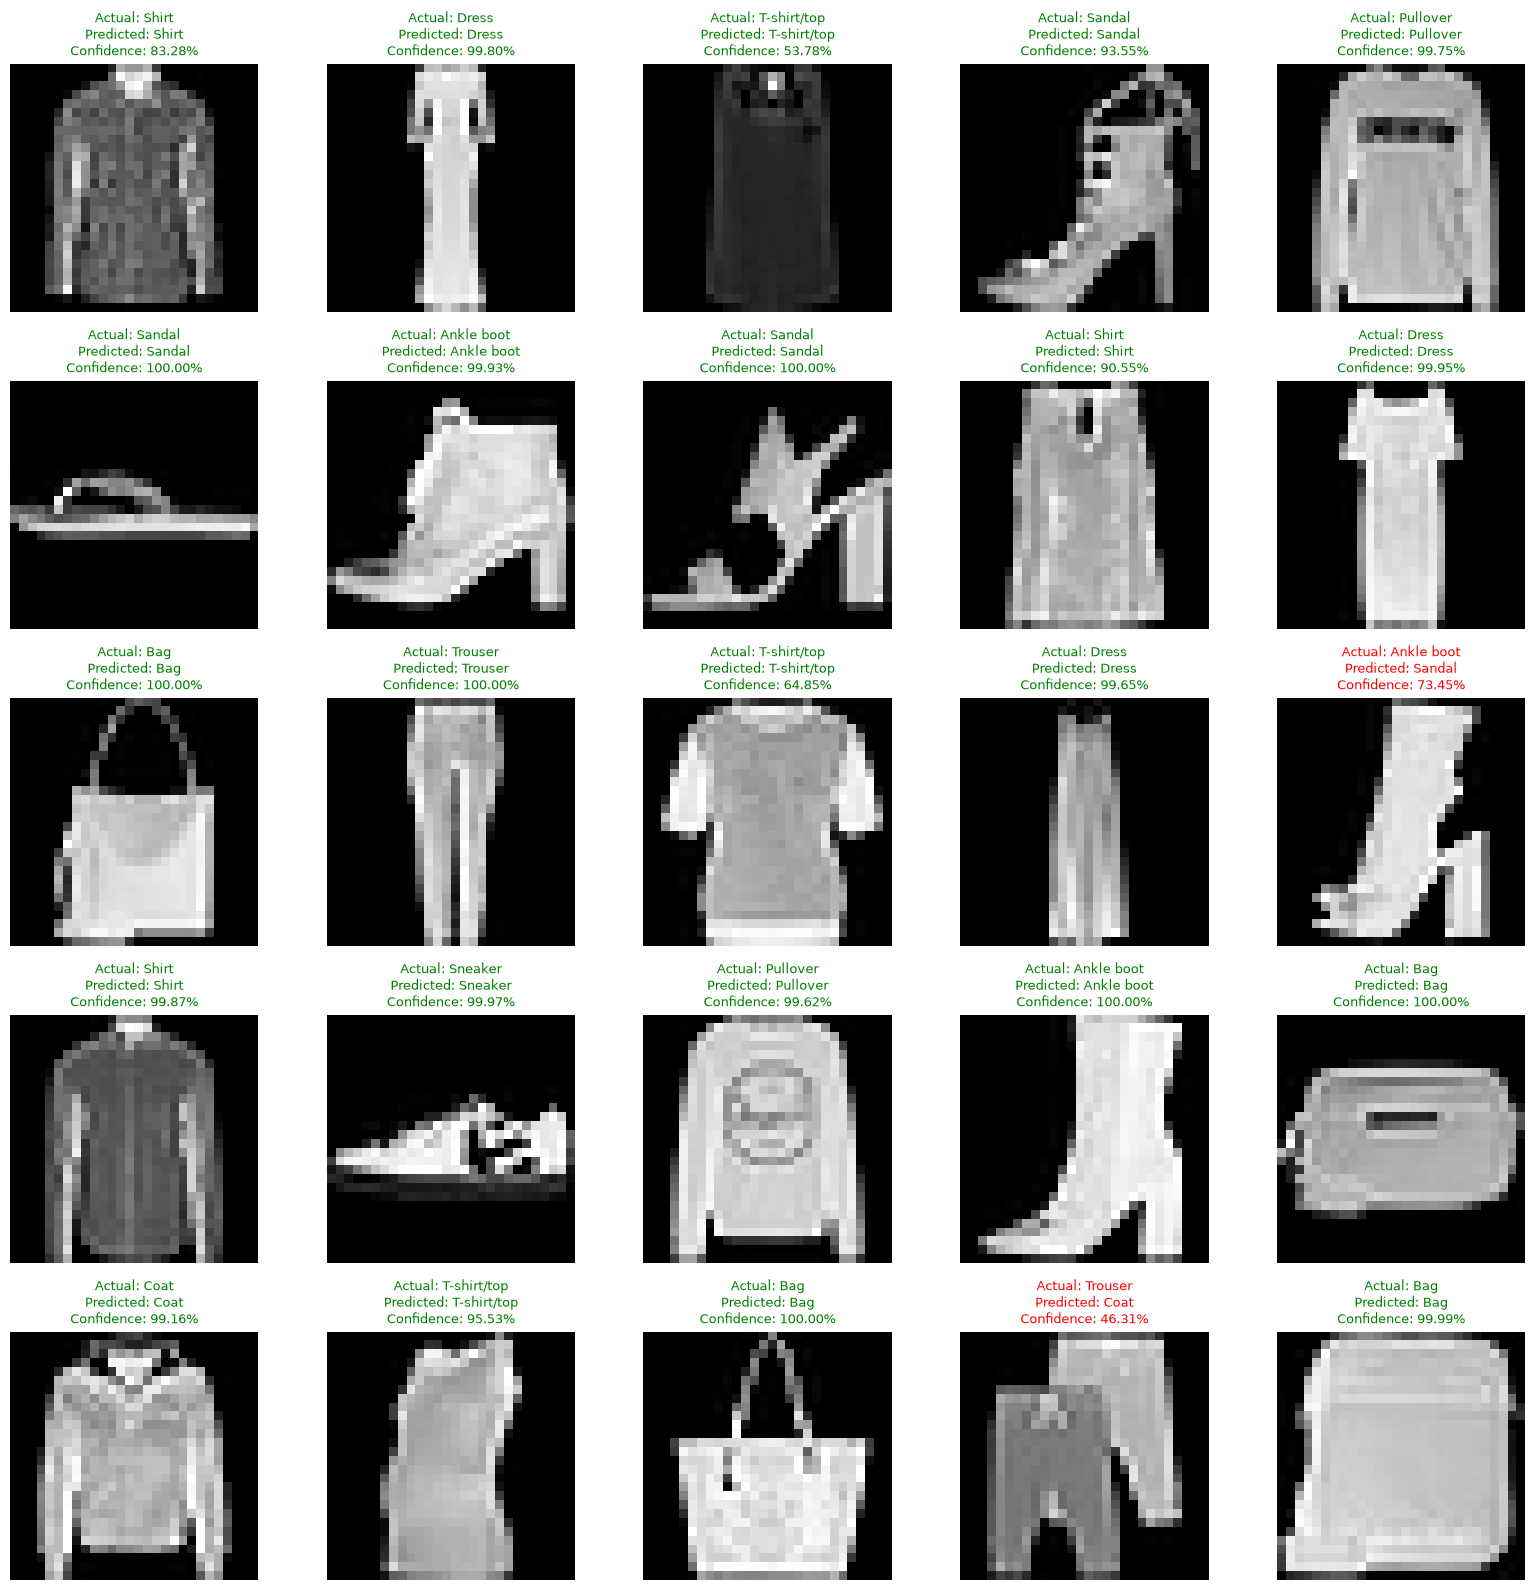

In [49]:
os.makedirs("../outputs/predictions", exist_ok=True)

plt.figure(figsize=(16, 16))

for position, index in enumerate(sample_indices):
    actual = y_test[index]
    predicted = y_pred[index]

    plt.subplot(5, 5, position + 1)
    plt.imshow(x_test[index], cmap="gray")

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}\n"
        f"Confidence: {confidence[index]:.2%}",
        color=color,
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig(
    "../outputs/predictions/25_test_predictions.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [50]:
import pandas as pd
import os

# Model comparison data
comparison_data = {
    "Model": ["MLP", "CNN", "Improved CNN"],

    "Parameters": [
        mlp_model.count_params(),
        cnn_model.count_params(),
        improved_cnn_model.count_params()
    ],

    "Epochs": [24, 18, 40],

    "Training_Time_Seconds": [
        55.35,
        678,
        3780  # Approximately 63 minutes
    ],

    "Validation_Accuracy_Percent": [
        89.97,
        93.30,
        93.61
    ],

    "Test_Accuracy_Percent": [
        88.38,
        92.04,
        92.44
    ],

    "Validation_Loss": [
        0.2920,
        0.2138,
        0.1753
    ],

    "Test_Loss": [
        mlp_test_loss,
        cnn_test_loss,
        improved_test_loss
    ]
}

# Create DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Create output directory
os.makedirs("../outputs", exist_ok=True)

# Save CSV
csv_path = "../outputs/model_comparison.csv"
comparison_df.to_csv(csv_path, index=False)

# Display results
print("Model comparison CSV saved successfully!")
display(comparison_df)
print("File location:", csv_path)

Model comparison CSV saved successfully!


,Model,Parameters,Epochs,Training_Time_Seconds,Validation_Accuracy_Percent,Test_Accuracy_Percent,Validation_Loss,Test_Loss
0,MLP,235146,24,55.35,89.97,88.38,0.2920,0.332385
1,CNN,422026,18,678.00,93.30,92.04,0.2138,0.237081
2,Improved CNN,469098,40,3780.00,93.61,92.44,0.1753,0.200784


File location: ../outputs/model_comparison.csv
